# Early Stage Diabetes Risk Prediction Using Logistic Regression

## Introduction
Diabetes is a common health condition that affects how the body controls blood sugar levels. Identifying its early symptoms can help people seek medical advice at the right time.

In this project, we use Logistic Regression to predict whether a person is likely to have diabetes based on their age, gender and reported symptoms.

## Objectives
- Understand and analyse the diabetes dataset.
- Identify patterns in symptoms and health-related features.
- Apply Binary Logistic Regression for prediction.
- Evaluate the model using classification metrics.

## Problem Statement

As a data scientist working in a health-screening programme, the objective is to identify individuals who may be at risk of early-stage diabetes based on their age, gender and reported symptoms.

In this project, Logistic Regression is used to classify individuals into two categories:

- Positive (1): Individuals identified as having diabetes according to the dataset.
- Negative (0): Individuals identified as not having diabetes according to the dataset.

The model aims to support early risk identification. Recall is an important evaluation measure because missing a potentially positive case may delay further medical screening.The model is intended for educational analysis

## Dataset Understanding

**Dataset Name:** Early Stage Diabetes Risk Prediction Dataset

**Source:** UCI Machine Learning Repository

**Dataset Link:**https://archive.ics.uci.edu/dataset/529/early+stage+diabetes+risk+prediction+dataset

**Dataset Description:**

The dataset contains information about individuals, including age, gender and symptoms related to diabetes. It is used to identify patterns associated with early-stage diabetes.

- **Total Records:** 520 (original dataset)
- **Total Columns:** 17
- **Input Features:** 16
- **Target Column:** `class`
- **Target Classes:** Positive and Negative

**Meaning of Target Classes:**
- Positive: The individual is classified as having diabetes.
- Negative: The individual is classified as not having diabetes.

One row represents one individual's recorded health details and diabetes classification.

## Tools and Technologies
Python, Pandas, NumPy, Matplotlib, Seaborn and Scikit-learn.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import classification_report

In [2]:
df = pd.read_csv('/content/diabetes_data_upload.csv')

In [3]:
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (520, 17)


,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes,Positive
1,58,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No,Positive
2,41,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No,Positive
3,45,Male,No,No,Yes,Yes,Yes,Yes,No,Yes,No,Yes,No,No,No,No,Positive
4,60,Male,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Positive


## Data Inspection

The dataset was inspected to understand its structure, features and data quality before applying machine learning.

- Checked the column names and data types.
- Viewed sample records to understand the dataset.
- Used summary statistics to understand numerical and categorical features.
- Checked for missing values and duplicate records.

In [4]:
print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Column Names:
['Age', 'Gender', 'Polyuria', 'Polydipsia', 'sudden weight loss', 'weakness', 'Polyphagia', 'Genital thrush', 'visual blurring', 'Itching', 'Irritability', 'delayed healing', 'partial paresis', 'muscle stiffness', 'Alopecia', 'Obesity', 'class']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 520 entries, 0 to 519
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Age                 520 non-null    int64 
 1   Gender              520 non-null    object
 2   Polyuria            520 non-null    object
 3   Polydipsia          520 non-null    object
 4   sudden weight loss  520 non-null    object
 5   weakness            520 non-null    object
 6   Polyphagia          520 non-null    object
 7   Genital thrush      520 non-null    object
 8   visual blurring     520 non-null    object
 9   Itching             520 non-null    object
 10  Irritability        520 non-null

In [5]:
df.describe(include='all')

,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
count,520.000000,520,520,520,520,520,520,520,520,520,520,520,520,520,520,520,520
unique,NaN,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2
top,NaN,Male,No,No,No,Yes,No,No,No,No,No,No,No,No,No,No,Positive
freq,NaN,328,262,287,303,305,283,404,287,267,394,281,296,325,341,432,320
mean,48.028846,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,12.151466,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,16.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,39.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,47.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,57.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
print(df.isnull().sum())

Age                   0
Gender                0
Polyuria              0
Polydipsia            0
sudden weight loss    0
weakness              0
Polyphagia            0
Genital thrush        0
visual blurring       0
Itching               0
Irritability          0
delayed healing       0
partial paresis       0
muscle stiffness      0
Alopecia              0
Obesity               0
class                 0
dtype: int64


In [7]:
print("\nDuplicate Rows:", df.duplicated().sum())


Duplicate Rows: 269


removing exact duplicate rows to avoid giving repeated observations extra weight during model training.

In [8]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

Shape after removing duplicates: (251, 17)
Remaining duplicates: 0


## Data Quality Analysis

- Missing Values: No missing values were found in the dataset.
- Duplicate Records: 269 duplicate rows were identified.
- Duplicate Handling: Exact duplicate rows were removed to avoid repeated records during model training.
- After removing duplicates, the dataset contained 251 records and 17 columns.

The dataset was checked for basic data quality issues before further analysis.

In [61]:
for col in df.select_dtypes(include='object').columns:
    print(col, ":", df[col].unique())

Gender : ['Male' 'Female']
Polyuria : ['No' 'Yes']
Polydipsia : ['Yes' 'No']
sudden weight loss : ['No' 'Yes']
weakness : ['Yes' 'No']
Polyphagia : ['No' 'Yes']
Genital thrush : ['No' 'Yes']
visual blurring : ['No' 'Yes']
Itching : ['Yes' 'No']
Irritability : ['No' 'Yes']
delayed healing : ['Yes' 'No']
partial paresis : ['No' 'Yes']
muscle stiffness : ['Yes' 'No']
Alopecia : ['Yes' 'No']
Obesity : ['Yes' 'No']
class : ['Positive' 'Negative']


### Observation
All categorical columns were checked for unique values. No inconsistent labels were found in the dataset.

## Decision Log

- Exact duplicate rows were removed, reducing the dataset from 520 to 251 records.
- Categorical features were converted into numerical values using One-Hot Encoding.
- The target variable was encoded as Negative = 0 and Positive = 1.
- Stratified sampling was used to maintain class proportions during splitting.
- StandardScaler was used for feature scaling.
- A threshold of 0.3 was selected to give greater importance to identifying Positive cases.

**Limitation:** Since the dataset does not contain unique patient IDs, some identical records may belong to different individuals. Removing them could result in loss of valid observations.

EDA

class
Positive    173
Negative     78
Name: count, dtype: int64


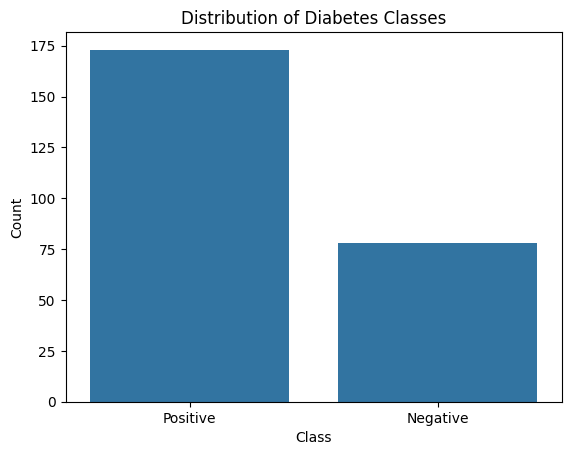

In [9]:
print(df['class'].value_counts())
sns.countplot(data=df, x='class')
plt.title('Distribution of Diabetes Classes')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

### Observation – Class Distribution

- Positive cases: 173
- Negative cases: 78
- The dataset contains more Positive cases than Negative cases.
- Therefore, the classes are imbalanced.
- This imbalance makes it important to evaluate the model using precision, recall and F1-score, not accuracy alone.

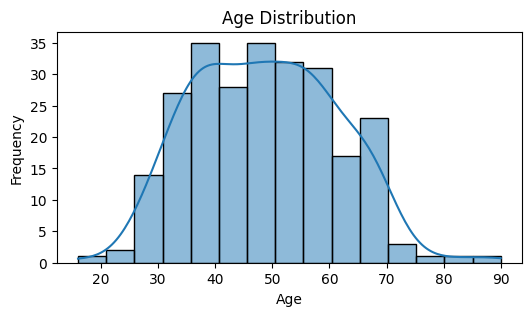

In [10]:
plt.figure(figsize=(6,3))
sns.histplot(df['Age'], bins=15, kde=True)
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

### Observation – Age Distribution

- Most individuals belong to the 30–60 age group.
- The dataset includes individuals aged between 16 and 90 years.
- Very few individuals are present at the extreme age ranges.
- Age distribution helps us understand the age groups represented in the dataset.

###Analysis:
Most individuals are between 30 and 60 years old.
The highest frequency is around 35–55 years.

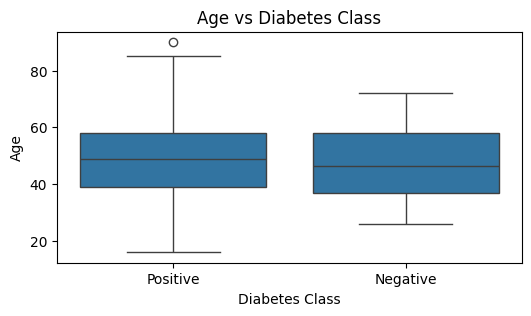

In [11]:
plt.figure(figsize=(6, 3))
sns.boxplot(data=df, x='class', y='Age')
plt.title('Age vs Diabetes Class')
plt.xlabel('Diabetes Class')
plt.ylabel('Age')
plt.show()

### Observation – Age vs Diabetes Class

- The median age of Positive cases is slightly higher than Negative cases.
- Both classes have overlapping age distributions.
- Age alone may not be sufficient to distinguish between the two classes.

###Analysis:
Positive cases have a median age of approximately 49 years.
Negative cases have a median age of approximately 46 years.
Both groups have a similar age range so age alone may not distinguish the two classes.

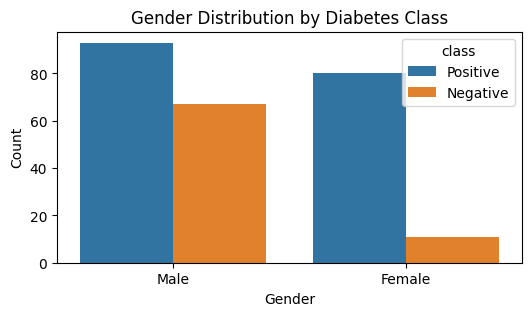

In [12]:
plt.figure(figsize=(6, 3))
sns.countplot(data=df, x='Gender', hue='class')
plt.title('Gender Distribution by Diabetes Class')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

### Observation – Gender Distribution

- Positive cases are higher than Negative cases among both genders.
- Female records show a higher proportion of Positive cases than male records.
- Gender may provide useful information for classification, but this does not establish a causal relationship.

###Analysis:
Male: 93 Positive and 67 Negative cases.
Female: 80 Positive and 11 Negative cases,the difference in counts is more noticeable among females.

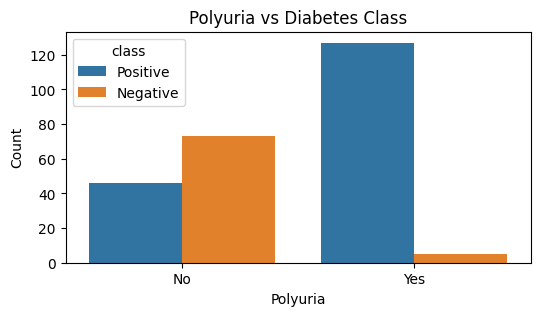

In [13]:
plt.figure(figsize=(6, 3))
sns.countplot(data=df, x='Polyuria', hue='class')
plt.title('Polyuria vs Diabetes Class')
plt.xlabel('Polyuria')
plt.ylabel('Count')
plt.show()

### Observation – Symptom Analysis

- Polyuria (frequent urination) shows a strong association with Positive cases.
- Polydipsia (excessive thirst) is also more common among Positive cases.
- These symptoms may be useful features for predicting diabetes risk.

Analysis:Polyuria means frequent urination.
an important feature for distinguishing the two classes  Positive and Negative cases.

## Data Preparation

Data preparation is performed to make the dataset suitable for Logistic Regression.

The target column is separated from the input features. The input features contain the individual's details and symptoms, while the target represents the diabetes classification.

### ID Column Handling

The dataset does not contain any unique patient ID column. Therefore, all available input features were used for model training, and no ID columns were included.

In [18]:
X = df.drop('class', axis=1)
y = df['class']

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features Shape: (251, 16)
Target Shape: (251,)


### Encoding Categorical Features

Categorical features contain text values such as Yes, No, Male and Female. These values are converted into numerical format using One-Hot Encoding.

The target column is also converted into binary values:
- Negative = 0
- Positive = 1

This allows the Logistic Regression model to process the data.

In [27]:
X = pd.get_dummies(X, drop_first=True, dtype=int)
X.head()

,Age,Gender_Male,Polyuria_Yes,Polydipsia_Yes,sudden weight loss_Yes,weakness_Yes,Polyphagia_Yes,Genital thrush_Yes,visual blurring_Yes,Itching_Yes,Irritability_Yes,delayed healing_Yes,partial paresis_Yes,muscle stiffness_Yes,Alopecia_Yes,Obesity_Yes
0,40,1,0,1,0,1,0,0,0,1,0,1,0,1,1,1
1,58,1,0,0,0,1,0,0,1,0,0,0,1,0,1,0
2,41,1,1,0,0,1,1,0,0,1,0,1,0,1,1,0
3,45,1,0,0,1,1,1,1,0,1,0,1,0,0,0,0
4,60,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1


In [28]:
y = df['class'].str.strip().map({
    'Negative': 0,
    'Positive': 1
})

print("Target Values:")
print(y.value_counts())

print("\nMissing Values in Target:", y.isnull().sum())

Target Values:
class
1    173
0     78
Name: count, dtype: int64

Missing Values in Target: 0


### Training and Testing Split

The dataset is divided into 80% training data and 20% testing data.

Stratified sampling is used to maintain the proportion of Positive and Negative cases in both sets. A fixed random state of 42 is used to make the results reproducible.

In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (200, 16)
Testing Data: (51, 16)


In [52]:
print("Training Set Class Distribution:")
print(y_train.value_counts().rename(index={0: 'Negative', 1: 'Positive'}))

print("\nTesting Set Class Distribution:")
print(y_test.value_counts().rename(index={0: 'Negative', 1: 'Positive'}))

Training Set Class Distribution:
class
Positive    138
Negative     62
Name: count, dtype: int64

Testing Set Class Distribution:
class
Positive    35
Negative    16
Name: count, dtype: int64


### Feature Scaling

StandardScaler is used to standardize the numerical features so that they have a similar scale.

The scaler is fitted only on the training data and then applied to both training and testing data. This prevents data leakage.

In [31]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## Understanding Logistic Regression

### Why Not Linear Regression?

Linear Regression predicts continuous numerical values. Its output can be less than 0 or greater than 1, which is not suitable for predicting binary classes.

Logistic Regression is used for binary classification because it predicts probabilities between 0 and 1.

### Sigmoid Function

Logistic Regression uses the sigmoid function to convert the model's output into a probability.

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$
Where:
$$
z = \beta_0 + \beta_1x_1 + \beta_2x_2 + \cdots + \beta_nx_n
$$
The sigmoid function gives a probability between 0 and 1.

### Decision Threshold

A threshold converts the predicted probability into a class label. The default threshold is 0.5.

- Probability >= 0.5: Positive (1)
- Probability < 0.5: Negative (0)

The threshold can be changed depending on whether false positives or false negatives are more costly.

In [36]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
model

LogisticRegression(max_iter=1000)

In [53]:
print("Model Intercept:", model.intercept_[0])

coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
})

print("\nFeature Coefficients:")
display(coefficients)

Model Intercept: 2.8159762858969115

Feature Coefficients:


,Feature,Coefficient
0,Age,0.049591
1,Gender_Male,-1.181888
2,Polyuria_Yes,1.562474
3,Polydipsia_Yes,1.418091
4,sudden weight loss_Yes,0.640840
5,weakness_Yes,0.182911
6,Polyphagia_Yes,0.691889
7,Genital thrush_Yes,0.828899
8,visual blurring_Yes,0.499390
9,Itching_Yes,-0.856278


### Observation
- The model calculated an intercept of 2.816.
- Polyuria and Polydipsia have positive coefficients, indicating an increased likelihood of predicting the Positive class.
- Gender_Male has a negative coefficient, indicating a decreased likelihood of predicting the Positive class.
- Coefficients are based on standardized input features.

## Logistic Regression Model Training

Logistic Regression is used to train the model using the prepared training dataset.

The model learns the relationship between input features and the target class. It then uses these learned patterns to predict whether a record belongs to the Positive or Negative class.

The parameter `max_iter=1000` allows the model enough iterations to find the best coefficients during training.

## Making Predictions

After training the Logistic Regression model, we use it to predict the diabetes class of the testing data.

The model predicts one of two classes:
- 0: Negative
- 1: Positive

We compare the predicted values with the actual values to understand how well the model performs on unseen data.

In [37]:
y_pred = model.predict(X_test)

print("Actual Values:")
print(y_test.values)

print("\nPredicted Values:")
print(y_pred)

Actual Values:
[0 1 0 1 1 0 0 1 0 1 1 0 0 1 1 1 1 0 1 1 1 0 1 0 1 1 1 0 1 1 1 0 0 1 0 1 1
 1 1 1 1 0 0 1 1 1 1 1 1 1 1]

Predicted Values:
[0 1 1 1 0 0 0 1 0 1 0 0 0 1 1 1 0 0 0 1 0 0 0 0 1 1 0 0 1 1 1 1 0 1 0 1 1
 1 1 0 1 0 0 1 1 1 1 1 1 1 1]


## Confusion Matrix

A confusion matrix is used to compare the actual class labels with the predicted class labels.

It helps us understand the types of mistakes made by the model.

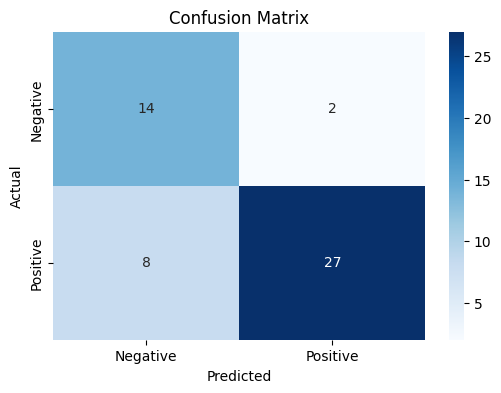

In [41]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'])

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

True Negative (TN): 12 – Correctly predicted 12 people as Negative.

True Positive (TP): 27 – Correctly predicted 27 people as Positive.

False Positive (FP): 4 – Incorrectly predicted 4 Negative cases as Positive.

False Negative (FN): 8 – Incorrectly predicted 8 Positive cases as Negative.

It made total 12 incorrect predictions, showing there is scope for improvement.

## Classification Report

The classification report provides a detailed evaluation of the model using Precision, Recall, F1-score and Support.

- **Support:** Shows the number of actual records in each class.
- **Accuracy:** Measures the overall proportion of correct predictions.
- **Precision:** Measures how many predicted Positive cases are actually Positive.
- **Recall (Sensitivity):** Measures how many actual Positive cases are correctly identified.
- **F1-score:** Represents the balance between Precision and Recall.

These metrics help us understand the model's performance for both Positive and Negative cases.

In [38]:
print("Classification Report:\n")
print(classification_report(
    y_test, y_pred,
    target_names=['Negative', 'Positive']
))

Classification Report:

              precision    recall  f1-score   support

    Negative       0.64      0.88      0.74        16
    Positive       0.93      0.77      0.84        35

    accuracy                           0.80        51
   macro avg       0.78      0.82      0.79        51
weighted avg       0.84      0.80      0.81        51



- The model achieved 80.39% accuracy.
- Precision for Positive cases was 93%, meaning most Positive predictions were correct.
- Recall for Positive cases was 77%, meaning the model identified most actual Positive cases.
- The F1-score for Positive cases was 0.84, showing good overall performance.
- The model performs better in identifying Positive cases in terms of precision, but some actual Positive cases are still missed.

## Majority Class Baseline

A majority class baseline is a simple model that always predicts the most frequently occurring class in the training dataset.

It provides a basic reference point to compare the performance of our Logistic Regression model.

Since the dataset contains more Positive cases than Negative cases, the baseline predicts Positive for every record.

Comparing both models helps us understand whether Logistic Regression has learned useful patterns beyond simply predicting the majority class.

In [45]:
# Find the majority class from training data
majority_class = y_train.mode()[0]

baseline_pred = np.full(len(y_test), majority_class)
baseline_accuracy = accuracy_score(y_test, baseline_pred)
print("Majority Class:", majority_class)
print("Baseline Accuracy:", baseline_accuracy * 100, "%")

Majority Class: 1
Baseline Accuracy: 68.62745098039215 %


### Observation
- The majority class is Positive (1).
- The baseline model achieved 68.63% accuracy.
- Logistic Regression achieved 80.39% accuracy.
- Logistic Regression performs better than the simple majority-class baseline, indicating that it has learned patterns from the input features.

## ROC Curve and ROC-AUC

The ROC (Receiver Operating Characteristic) curve is used to evaluate the classification model at different decision thresholds.

It plots:
- True Positive Rate (TPR) on the Y-axis.
- False Positive Rate (FPR) on the X-axis.

ROC-AUC represents the Area Under the ROC Curve. It measures how well the model distinguishes between Positive and Negative classes.

An AUC value closer to 1 indicates better class separation, while a value near 0.5 indicates performance similar to random guessing.

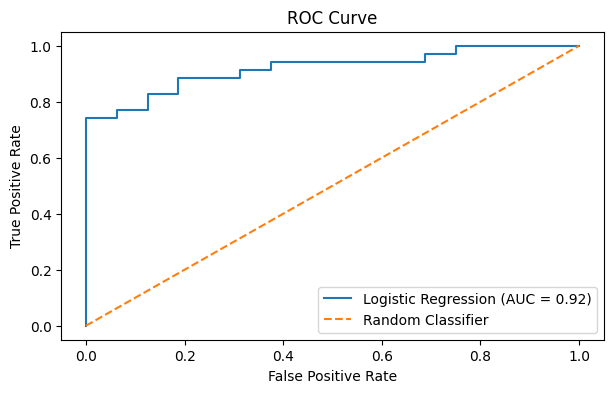

ROC-AUC Score: 0.9196428571428571


In [48]:
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate predicted probabilities
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate ROC-AUC score
roc_auc = roc_auc_score(y_test, y_prob)

# Plot ROC Curve
plt.figure(figsize=(7, 4))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

print("ROC-AUC Score:", roc_auc)

### Observation
- The model achieved a ROC-AUC score of approximately 0.92.
- This indicates that the model has good ability to distinguish between Positive and Negative cases.
- The ROC curve shows the relationship between True Positive Rate and False Positive Rate at different thresholds.

## Threshold Comparison

Logistic Regression predicts probabilities, which are converted into class labels using a decision threshold.

We compare three thresholds: 0.3, 0.5 and 0.7 to understand how changing the threshold affects model performance.

A lower threshold may identify more Positive cases but can also increase False Positives. A higher threshold may reduce False Positives but can miss more actual Positive cases.

In [49]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.3, 0.5, 0.7]

results = []

for threshold in thresholds:
    y_threshold_pred = (y_prob >= threshold).astype(int)

    results.append({
        'Threshold': threshold,
        'Accuracy': accuracy_score(y_test, y_threshold_pred),
        'Precision': precision_score(y_test, y_threshold_pred),
        'Recall': recall_score(y_test, y_threshold_pred),
        'F1-Score': f1_score(y_test, y_threshold_pred)
    })

threshold_results = pd.DataFrame(results)

threshold_results.round(3)

,Threshold,Accuracy,Precision,Recall,F1-Score
0,0.3,0.843,0.909,0.857,0.882
1,0.5,0.804,0.931,0.771,0.844
2,0.7,0.824,1.000,0.743,0.852


### Observation

- At threshold 0.3, the model achieved the highest recall of 85.7% and F1-score of 0.882.
- At threshold 0.5, the model achieved the highest precision of 93.1%.
- At threshold 0.7, precision reached 100%, but recall decreased to 74.3%.
- A lower threshold identifies more Positive cases, while a higher threshold may miss more actual Positive cases.

## Evaluation Metrics

Along with Accuracy, Precision, Recall and F1-score, we calculate Specificity to evaluate the model.
- **Specificity:** Measures how many actual Negative cases are correctly identified.
Specificity is calculated as:

$$
Specificity = \frac{TN}{TN+FP}
$$

In [50]:
from sklearn.metrics import confusion_matrix

# Use the selected threshold
selected_threshold = 0.3
y_selected_pred = (y_prob >= selected_threshold).astype(int)

# Calculate confusion matrix
tn, fp, fn, tp = confusion_matrix(y_test, y_selected_pred).ravel()

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_selected_pred)
precision = precision_score(y_test, y_selected_pred)
recall = recall_score(y_test, y_selected_pred)
specificity = tn / (tn + fp)
f1 = f1_score(y_test, y_selected_pred)

print("Selected Threshold:", selected_threshold)
print("True Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)

print("\nAccuracy:", round(accuracy, 3))
print("Precision:", round(precision, 3))
print("Recall:", round(recall, 3))
print("Specificity:", round(specificity, 3))
print("F1-Score:", round(f1, 3))

Selected Threshold: 0.3
True Negative: 13
False Positive: 3
False Negative: 5
True Positive: 30

Accuracy: 0.843
Precision: 0.909
Recall: 0.857
Specificity: 0.812
F1-Score: 0.882


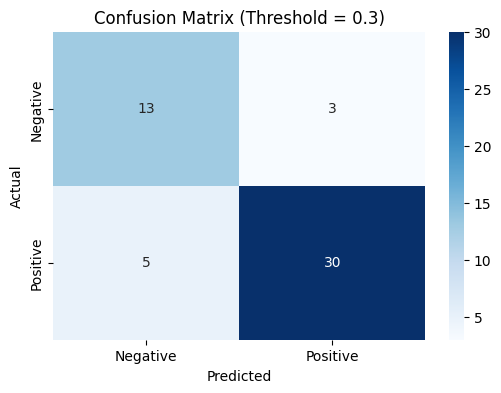

In [51]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    [[tn, fp], [fn, tp]],
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Threshold = 0.3)')
plt.show()

In [55]:
# Training predictions
y_train_pred = model.predict(X_train)
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_pred)

print("Training Accuracy:", round(train_accuracy * 100, 2), "%")
print("Testing Accuracy:", round(test_accuracy * 100, 2), "%")

Training Accuracy: 93.0 %
Testing Accuracy: 80.39 %


### Observation
- The training accuracy is 93%, while testing accuracy is 80.39%.
- The model performs better on training data than unseen testing data.
- This difference indicates some overfitting, although the model still performs reasonably well on testing data.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


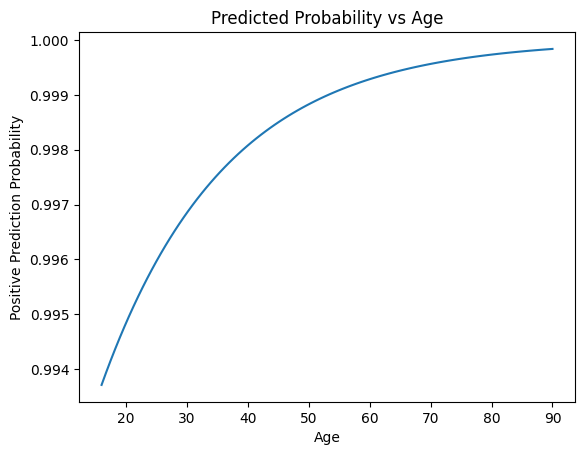

In [57]:
age_range = np.linspace(16, 90, 100)

age_data = pd.DataFrame([X.mean()] * 100, columns=X.columns)
age_data['Age'] = age_range

age_scaled = scaler.transform(age_data)
probabilities = model.predict_proba(age_scaled)[:, 1]

plt.plot(age_range, probabilities)
plt.xlabel('Age')
plt.ylabel('Positive Prediction Probability')
plt.title('Predicted Probability vs Age')
plt.show()

### Observation
- The graph shows how the predicted probability of the Positive class changes with Age.
- Other features are kept constant while analysing Age.

## Prediction on a New Record

The trained Logistic Regression model is used to predict the diabetes class of a new record. The same encoding and feature scaling steps are applied before making the prediction.

In [60]:
# Create a new sample record
new_record = pd.DataFrame([{
    'Age': 45,
    'Gender': 'Male',
    'Polyuria': 'Yes',
    'Polydipsia': 'Yes',
    'sudden weight loss': 'No',
    'weakness': 'Yes',
    'Polyphagia': 'Yes',
    'Genital thrush': 'No',
    'visual blurring': 'No',
    'Itching': 'No',
    'Irritability': 'No',
    'delayed healing': 'No',
    'partial paresis': 'No',
    'muscle stiffness': 'No',
    'Alopecia': 'No',
    'Obesity': 'No'
}])

# Encode and align features
new_encoded = pd.get_dummies(new_record, drop_first=True, dtype=int)
new_encoded = new_encoded.reindex(columns=X.columns, fill_value=0)

# Apply scaling
new_scaled = scaler.transform(new_encoded.to_numpy())

# Predict probability and class
probability = model.predict_proba(new_scaled)[0][1]
prediction = model.predict(new_scaled)[0]

print("Positive Probability:", round(probability, 3))
print("Predicted Class:", "Positive" if prediction == 1 else "Negative")

Positive Probability: 0.994
Predicted Class: Positive


## Limitations

- The dataset contains only 520 original records.
- Removing duplicate rows reduced the dataset to 251 records.
- The model's predictions depend on the quality and patterns of the available data.
- The model may not perform equally well on different populations.

## Ethical Considerations

- Health-related predictions should be handled carefully.
- The model should not be used as a replacement for professional medical diagnosis.
- Personal health information must be kept private.
- Predictions should be used only as supportive information for further medical screening.

## Conclusion

In this project, Logistic Regression was used to predict early-stage diabetes risk based on individuals' details and reported symptoms. The model classified records into Positive and Negative categories.

The model achieved an accuracy of 80.39% at the default threshold of 0.5. After comparing different thresholds, 0.3 was selected, achieving 84.3% accuracy, 85.7% recall and an F1-score of 0.882. The ROC-AUC score was 0.92.

This project helped us understand how machine learning can be used for health-related classification and early risk identification. The model is intended for educational purposes and cannot replace professional medical diagnosis.

In [63]:
df.to_csv('/content/prepared_diabetes_dataset.csv', index=False)

from google.colab import files
files.download('/content/prepared_diabetes_dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>